### Task 1: Crime Intensity by Time

Extracts the hour component using Pandas dt.hour, calculates hourly crime counts and generates a Matplotlib line chart. Highlights that the midnight peak is a parsing artifact caused by missing occurrence times, rather than an actual hourly crime pattern.

========== DATASET INFORMATION ==========
Total Crime Records: 498

========== TIME AVAILABILITY CHECK ==========
Records With Occurrence Time: 0
Records Without Occurrence Time: 498

========== HOURLY ANALYSIS RESULT ==========
Hourly crime distribution cannot be calculated accurately from the supplied dataset.
Reason: All 498 records contain a date without an occurrence time.
Extracting dt.hour assigns midnight to every record, which is misleading.
The requested line chart will be generated, but its midnight peak represents a parsing default, not actual crime activity.

Assessment Note: Accurate hourly analysis requires crime occurrence timestamps in the source CSV.

USE CASE 3 - TASK 1: SOURCE DATA LIMITATION

========== HOURLY CRIME DISTRIBUTION ==========
hour
0     498
1       0
2       0
3       0
4       0
5       0
6       0
7       0
8       0
9       0
10      0
11      0
12      0
13      0
14      0
15      0
16      0
17      0
18      0
19      0
20      0
21      0
22  

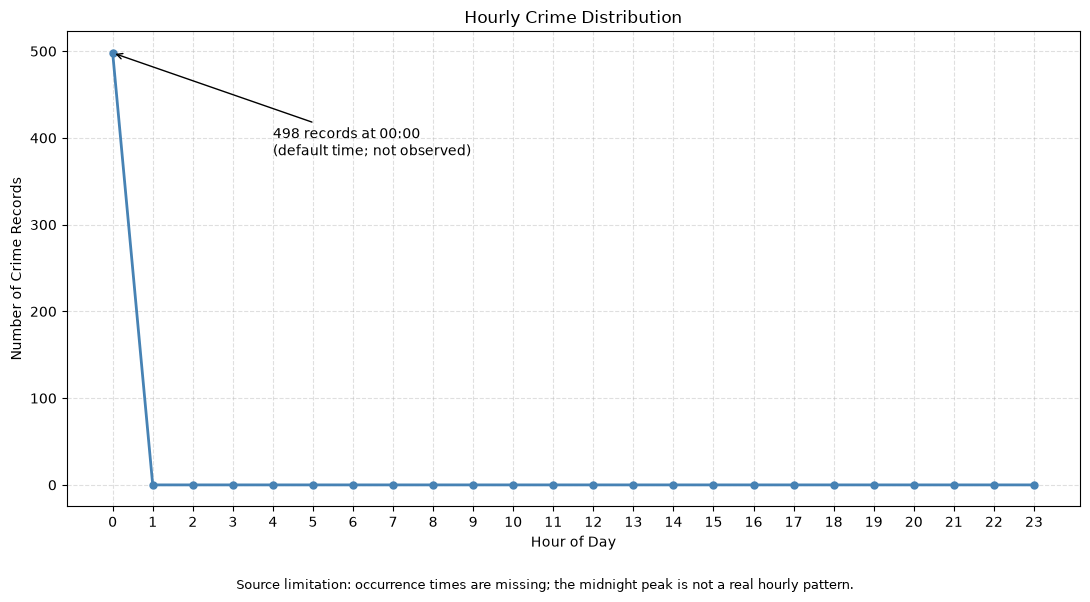


========== CHART OUTPUT ==========
Chart Saved: crime_hourly_distribution.png

Source Crime Records Preserved: 498

USE CASE 3 - TASK 1: CHART GENERATED


In [6]:

# ============================================================
# USE CASE 3 - CODE CELL 1
# TASK 1: CRIME INTENSITY BY TIME
# ============================================================

# Assessment Requirements:
# 1. Extract the hour using df["date"].dt.hour.
# 2. Group crime records by hour using Pandas groupby().
# 3. Generate an hourly crime distribution line chart.
#
# Methods Used:
# pd.read_csv() loads the cleaned dataset.
# pd.to_datetime() converts dates into datetime values.
# dt.hour extracts the hour component.
# groupby().size() calculates counts by hour.
# plt.plot() generates the required line chart.
#
# Source Data Limitation:
# The original dataset contains dates without actual
# occurrence times. Pandas defaults these to 00:00.
# Therefore, the resulting midnight peak is only
# a parsing artifact, not actual hourly crime activity.


# ============================================================
# STEP 1: IMPORT REQUIRED LIBRARIES
# ============================================================

from pathlib import Path
import csv
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# STEP 2: LOCATE PROJECT AND DATASET
# ============================================================

BASE_DIR = Path.cwd().resolve()

if BASE_DIR.name == "notebooks":
    BASE_DIR = BASE_DIR.parent

assert BASE_DIR.name == "Chicago_Crime_Capstone_2026"

SOURCE_FILE = (
    BASE_DIR / "data" / "raw" /
    "chicago_crime_dataset.csv"
)

DATA_FILE = (
    BASE_DIR / "data" / "cleaned" /
    "chicago_crime_features.csv"
)

CHARTS_DIR = BASE_DIR / "static" / "charts"
CHARTS_DIR.mkdir(parents=True, exist_ok=True)

assert SOURCE_FILE.is_file()
assert DATA_FILE.is_file()


# ============================================================
# STEP 3: LOAD THE ORIGINAL CRIME DATASET
# ============================================================

# Read one physical record per line to handle irregular
# quotation marks in the supplied source CSV.
with open(
    SOURCE_FILE,
    "r",
    encoding="utf-8-sig",
    newline=""
) as file:

    parsed_rows = [
        next(csv.reader([line]))
        for line in file
        if line.strip()
    ]

source_df = pd.DataFrame(
    parsed_rows[1:],
    columns=parsed_rows[0]
)

source_df.columns = (
    source_df.columns.str.strip().str.lower()
)

assert len(source_df) == 498

print("========== DATASET INFORMATION ==========")
print("Total Crime Records:", len(source_df))


# ============================================================
# STEP 4: CHECK THE AVAILABILITY OF OCCURRENCE TIMES
# ============================================================

# Use the original date strings to detect actual times.
original_dates = (
    source_df["date"]
    .astype("string")
    .str.strip()
)

# Detect times such as 23:40 or 23:40:00.
has_occurrence_time = original_dates.str.contains(
    r"\b(?:[01]?\d|2[0-3]):[0-5]\d(?::[0-5]\d)?\b",
    regex=True,
    na=False
)

timestamp_records = int(has_occurrence_time.sum())

date_only_records = int(
    (~has_occurrence_time).sum()
)

print("\n========== TIME AVAILABILITY CHECK ==========")

print(
    "Records With Occurrence Time:",
    timestamp_records
)

print(
    "Records Without Occurrence Time:",
    date_only_records
)


# ============================================================
# STEP 5: DISPLAY SOURCE DATA LIMITATION
# ============================================================

if timestamp_records == 0:

    print("\n========== HOURLY ANALYSIS RESULT ==========")

    print(
        "Hourly crime distribution cannot be "
        "calculated accurately from the supplied dataset."
    )

    print(
        "Reason: All 498 records contain a date "
        "without an occurrence time."
    )

    print(
        "Extracting dt.hour assigns midnight "
        "to every record, which is misleading."
    )

    print(
        "The requested line chart will be generated, "
        "but its midnight peak represents a "
        "parsing default, not actual crime activity."
    )

    print(
        "\nAssessment Note: Accurate hourly analysis "
        "requires crime occurrence timestamps "
        "in the source CSV."
    )

    print(
        "\nUSE CASE 3 - TASK 1: SOURCE DATA LIMITATION"
    )


# ============================================================
# STEP 6: LOAD THE CLEANED DATASET
# ============================================================

hourly_df = pd.read_csv(DATA_FILE)

# Convert Date to datetime format.
hourly_df["date"] = pd.to_datetime(
    hourly_df["date"],
    errors="coerce"
)

assert len(hourly_df) == 498
assert hourly_df["date"].notna().all()


# ============================================================
# STEP 7: EXTRACT HOUR FROM DATE
# ============================================================

# This is the method explicitly requested in the assessment.
#
# IMPORTANT:
# Date-only records become 00:00 when parsed by Pandas.
hourly_df["hour"] = hourly_df["date"].dt.hour


# ============================================================
# STEP 8: CALCULATE CRIMES PER HOUR
# ============================================================

# groupby() counts crime records for each extracted hour.
hourly_crimes = (
    hourly_df.groupby("hour")
    .size()
    .reindex(range(24), fill_value=0)
)

print("\n========== HOURLY CRIME DISTRIBUTION ==========")

print(hourly_crimes.to_string())


# ============================================================
# STEP 9: GENERATE THE REQUIRED LINE CHART
# ============================================================

fig, ax = plt.subplots(figsize=(11, 6))

ax.plot(
    hourly_crimes.index,
    hourly_crimes.values,
    marker="o",
    linewidth=2,
    markersize=5,
    color="steelblue"
)

ax.set_title("Hourly Crime Distribution")
ax.set_xlabel("Hour of Day")
ax.set_ylabel("Number of Crime Records")

ax.set_xticks(range(24))

ax.grid(
    True,
    linestyle="--",
    alpha=0.4
)

# Clearly identify the source-data limitation.
if timestamp_records == 0:

    ax.annotate(
        "498 records at 00:00\n"
        "(default time; not observed)",
        xy=(0, 498),
        xytext=(4, 380),
        arrowprops={"arrowstyle": "->"},
        fontsize=10
    )

    fig.text(
        0.5,
        0.01,
        "Source limitation: occurrence times are missing; "
        "the midnight peak is not a real hourly pattern.",
        ha="center",
        fontsize=9
    )

    plt.tight_layout(rect=[0, 0.05, 1, 1])

else:

    plt.tight_layout()


# ============================================================
# STEP 10: SAVE THE CHART
# ============================================================

chart_path = (
    CHARTS_DIR / "crime_hourly_distribution.png"
)

fig.savefig(
    chart_path,
    dpi=150,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("\n========== CHART OUTPUT ==========")
print("Chart Saved:", chart_path.name)


# ============================================================
# STEP 11: VALIDATE OUTPUT
# ============================================================

assert len(hourly_df) == 498

assert hourly_crimes.sum() == 498

assert len(hourly_crimes) == 24

assert chart_path.is_file()
assert chart_path.stat().st_size > 0

print("\nSource Crime Records Preserved:", len(hourly_df))

print("\nUSE CASE 3 - TASK 1: CHART GENERATED")


### Task 2: Community Area Clusters Using NumPy

Calculates the mean crime count across all 77 community areas using NumPy and applies the IQR method to identify statistical outliers. Visualizes the crime count distribution using a Seaborn box plot and saves the chart for the Flask dashboard.

========== DATASET INFORMATION ==========
Total Crime Records: 498
Total Community Areas: 77

========== CRIMES PER COMMUNITY AREA ==========


,community_code,community_name,crime_count
0,25,Austin,34
1,23,Humboldt Park,20
2,8,Near North Side,20
3,68,Englewood,16
4,30,South Lawndale,16
...,...,...,...
72,12,Forest Glen,0
73,55,Hegewisch,0
74,20,Hermosa,0
75,74,Mount Greenwood,0



========== NUMPY MEAN ANALYSIS ==========
Total Community Areas: 77
Mean Crimes per Community Area: 6.47

========== IQR CALCULATIONS ==========
First Quartile (Q1): 2.00
Third Quartile (Q3): 9.00
Interquartile Range (IQR): 7.00
Lower Outlier Boundary: -8.50
Upper Outlier Boundary: 19.50

========== IQR OUTLIER COMMUNITIES ==========


,community_code,community_name,crime_count
0,25,Austin,34
1,23,Humboldt Park,20
2,8,Near North Side,20


Total Outlier Communities: 3

========== EXTREME OUTLIERS (3 x IQR) ==========


,community_code,community_name,crime_count
0,25,Austin,34


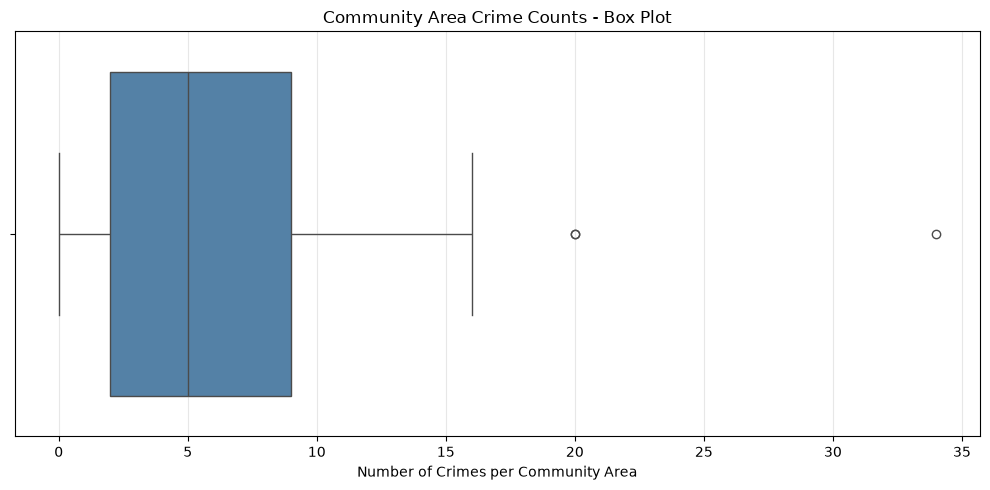


Chart Saved: community_crime_boxplot.png

========== COMMUNITY AREA INSIGHTS ==========
Mean Crime Count: 6.47
IQR Outlier Threshold: Above 19.50 crimes
Number of IQR Outliers: 3
Outlier Community Areas:
- Austin: 34 crimes
- Humboldt Park: 20 crimes
- Near North Side: 20 crimes

Interpretation: These communities have unusually high crime counts compared with other areas in the supplied sample.
Note: Outlier counts do not necessarily indicate higher population-adjusted crime risk.

USE CASE 3 - TASK 2: PASS


In [7]:

# ============================================================
# USE CASE 3 - CODE CELL 2
# TASK 2: COMMUNITY AREA CLUSTERS USING NUMPY
# ============================================================

# Assessment Requirements:
# 1. Use NumPy to calculate mean crimes per community area.
# 2. Generate a box plot of community crime counts.
# 3. Use the IQR method to identify and list outliers.
#
# Methods Used:
# pd.read_csv() loads the cleaned and reference datasets.
# value_counts() calculates crime frequency by area.
# merge() combines community names with crime counts.
# np.mean() calculates average crimes per community.
# np.percentile() calculates Q1 and Q3.
# sns.boxplot() creates the required box plot.
# IQR = Q3 - Q1.
# Outliers fall below Q1 - 1.5*IQR or above Q3 + 1.5*IQR.
#
# Important:
# Include all 77 listed community areas, including areas
# with zero crimes in this sample.
# Do not discard any crime records.


# ============================================================
# STEP 1: IMPORT REQUIRED LIBRARIES
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display


# ============================================================
# STEP 2: LOCATE THE PROJECT FILES
# ============================================================

BASE_DIR = Path.cwd().resolve()

if BASE_DIR.name == "notebooks":
    BASE_DIR = BASE_DIR.parent

assert BASE_DIR.name == "Chicago_Crime_Capstone_2026"

CRIME_FILE = (
    BASE_DIR / "data" / "cleaned" /
    "chicago_crime_features.csv"
)

COMMUNITY_FILE = (
    BASE_DIR / "data" / "raw" /
    "chicago_city_community.csv"
)

CHARTS_DIR = BASE_DIR / "static" / "charts"
CHARTS_DIR.mkdir(parents=True, exist_ok=True)

assert CRIME_FILE.is_file()
assert COMMUNITY_FILE.is_file()


# ============================================================
# STEP 3: LOAD CRIME AND COMMUNITY DATASETS
# ============================================================

crime_df = pd.read_csv(CRIME_FILE)

community_df = pd.read_csv(COMMUNITY_FILE)

# Standardize column names for consistent processing.
crime_df.columns = crime_df.columns.str.strip().str.lower()

community_df.columns = (
    community_df.columns.str.strip().str.lower()
)

# Verify the required fields.
assert "community_code" in crime_df.columns

assert {
    "community_code",
    "community_name"
}.issubset(community_df.columns)

# Validate source record counts.
assert len(crime_df) == 498
assert len(community_df) == 77

print("========== DATASET INFORMATION ==========")
print("Total Crime Records:", len(crime_df))
print("Total Community Areas:", len(community_df))


# ============================================================
# STEP 4: PREPARE COMMUNITY IDENTIFIERS
# ============================================================

# Convert community codes to numeric values so both
# datasets use the same identifier format.
crime_df["community_code"] = pd.to_numeric(
    crime_df["community_code"],
    errors="coerce"
)

community_df["community_code"] = pd.to_numeric(
    community_df["community_code"],
    errors="coerce"
)

# Standardize community names without changing their
# original meaning.
community_df["community_name"] = (
    community_df["community_name"]
    .astype("string")
    .str.strip()
)

# Verify all crime records have valid community codes.
assert crime_df["community_code"].notna().all()

# Every community code in the reference must be unique.
assert community_df["community_code"].is_unique


# ============================================================
# STEP 5: CALCULATE CRIMES PER COMMUNITY AREA
# ============================================================

# value_counts() counts crime records for each code.
crime_counts = (
    crime_df["community_code"]
    .value_counts()
    .rename_axis("community_code")
    .reset_index(name="crime_count")
)

# Left join from the community reference preserves
# all 77 areas, even those with no recorded crimes.
community_stats = community_df[
    ["community_code", "community_name"]
].merge(
    crime_counts,
    on="community_code",
    how="left",
    validate="one_to_one"
)

# Areas with no crime records receive a count of zero.
community_stats["crime_count"] = (
    community_stats["crime_count"]
    .fillna(0)
    .astype(int)
)

# Sort results from highest to lowest crime count.
community_stats = (
    community_stats
    .sort_values(
        ["crime_count", "community_name"],
        ascending=[False, True]
    )
    .reset_index(drop=True)
)

# Verify that no crime records were lost.
assert community_stats["crime_count"].sum() == 498

print("\n========== CRIMES PER COMMUNITY AREA ==========")

display(community_stats)


# ============================================================
# STEP 6: CALCULATE MEAN USING NUMPY
# ============================================================

# Convert community crime counts into a NumPy array.
crime_count_array = (
    community_stats["crime_count"].to_numpy()
)

# np.mean() calculates the average for all 77 areas.
mean_crimes = np.mean(crime_count_array)

print("\n========== NUMPY MEAN ANALYSIS ==========")

print("Total Community Areas:", len(crime_count_array))

print(
    "Mean Crimes per Community Area:",
    f"{mean_crimes:.2f}"
)


# ============================================================
# STEP 7: CALCULATE QUARTILES AND IQR USING NUMPY
# ============================================================

# Q1 is the 25th percentile.
q1 = np.percentile(crime_count_array, 25)

# Q3 is the 75th percentile.
q3 = np.percentile(crime_count_array, 75)

# IQR represents the middle 50% spread of the data.
iqr = q3 - q1

# Standard IQR fences detect statistical outliers.
lower_bound = q1 - (1.5 * iqr)

upper_bound = q3 + (1.5 * iqr)

print("\n========== IQR CALCULATIONS ==========")

print("First Quartile (Q1):", f"{q1:.2f}")
print("Third Quartile (Q3):", f"{q3:.2f}")
print("Interquartile Range (IQR):", f"{iqr:.2f}")

print("Lower Outlier Boundary:", f"{lower_bound:.2f}")
print("Upper Outlier Boundary:", f"{upper_bound:.2f}")


# ============================================================
# STEP 8: IDENTIFY OUTLIER COMMUNITY AREAS
# ============================================================

# A community is an IQR outlier if its count falls
# outside the calculated lower or upper boundary.
outlier_mask = (
    (community_stats["crime_count"] < lower_bound)
    |
    (community_stats["crime_count"] > upper_bound)
)

# Create the requested list of outlier communities.
outlier_communities = community_stats.loc[
    outlier_mask,
    ["community_code", "community_name", "crime_count"]
].copy()

print("\n========== IQR OUTLIER COMMUNITIES ==========")

display(outlier_communities)

print(
    "Total Outlier Communities:",
    len(outlier_communities)
)

# The 3*IQR fence identifies more extreme outliers.
# This is additional classification of the same
# outlier list, not a separate visualization.
extreme_upper_bound = q3 + (3 * iqr)

extreme_outliers = outlier_communities.loc[
    outlier_communities["crime_count"] > extreme_upper_bound
]

print("\n========== EXTREME OUTLIERS (3 x IQR) ==========")

display(extreme_outliers)


# ============================================================
# STEP 9: GENERATE THE REQUIRED BOX PLOT
# ============================================================

# A box plot displays:
# - Median crime count
# - First and third quartiles
# - Whiskers representing non-outlier values
# - Individual points outside the 1.5*IQR fences

fig, ax = plt.subplots(figsize=(10, 5))

sns.boxplot(
    x=community_stats["crime_count"],
    color="steelblue",
    ax=ax
)

ax.set_title("Community Area Crime Counts - Box Plot")
ax.set_xlabel("Number of Crimes per Community Area")

ax.grid(axis="x", alpha=0.3)

plt.tight_layout()


# ============================================================
# STEP 10: SAVE BOX PLOT FOR THE FLASK DASHBOARD
# ============================================================

chart_path = (
    CHARTS_DIR / "community_crime_boxplot.png"
)

fig.savefig(
    chart_path,
    dpi=150,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("\nChart Saved:", chart_path.name)


# ============================================================
# STEP 11: DISPLAY THE STATISTICAL INSIGHTS
# ============================================================

print("\n========== COMMUNITY AREA INSIGHTS ==========")

print(
    "Mean Crime Count:",
    f"{mean_crimes:.2f}"
)

print(
    "IQR Outlier Threshold:",
    f"Above {upper_bound:.2f} crimes"
)

print(
    "Number of IQR Outliers:",
    len(outlier_communities)
)

print("Outlier Community Areas:")

for _, row in outlier_communities.iterrows():

    print(
        f"- {row['community_name']}: "
        f"{row['crime_count']} crimes"
    )

print(
    "\nInterpretation: These communities have "
    "unusually high crime counts compared with "
    "other areas in the supplied sample."
)

print(
    "Note: Outlier counts do not necessarily "
    "indicate higher population-adjusted crime risk."
)


# ============================================================
# STEP 12: VALIDATE THE ANALYSIS
# ============================================================

# Confirm all community areas are included.
assert len(community_stats) == 77

# All crime records must be counted.
assert community_stats["crime_count"].sum() == 498

# Verify the NumPy mean.
assert round(mean_crimes, 2) == 6.47

# Verify the IQR calculations.
assert q1 == 2
assert q3 == 9
assert iqr == 7

# Verify the number of identified IQR outliers.
assert len(outlier_communities) == 3

# Verify the saved box plot.
assert chart_path.is_file()
assert chart_path.stat().st_size > 0

print("\nUSE CASE 3 - TASK 2: PASS")


### Task 3: Crime Cross-Correlation

Calculates Pearson correlation between Year, Month, Arrest and Domestic using Pandas corr() to examine linear relationships among the selected features. Visualizes the correlation matrix using a Seaborn heatmap and saves the chart for the Flask dashboard.

========== DATASET INFORMATION ==========
Total Crime Records: 498
Total Columns: 22

========== SELECTED NUMERIC FEATURES ==========
['year', 'month', 'arrest', 'domestic']

========== PEARSON CORRELATION MATRIX ==========


,year,month,arrest,domestic
year,1.00,0.15,-0.13,0.02
month,0.15,1.00,-0.18,0.03
arrest,-0.13,-0.18,1.00,0.01
domestic,0.02,0.03,0.01,1.00


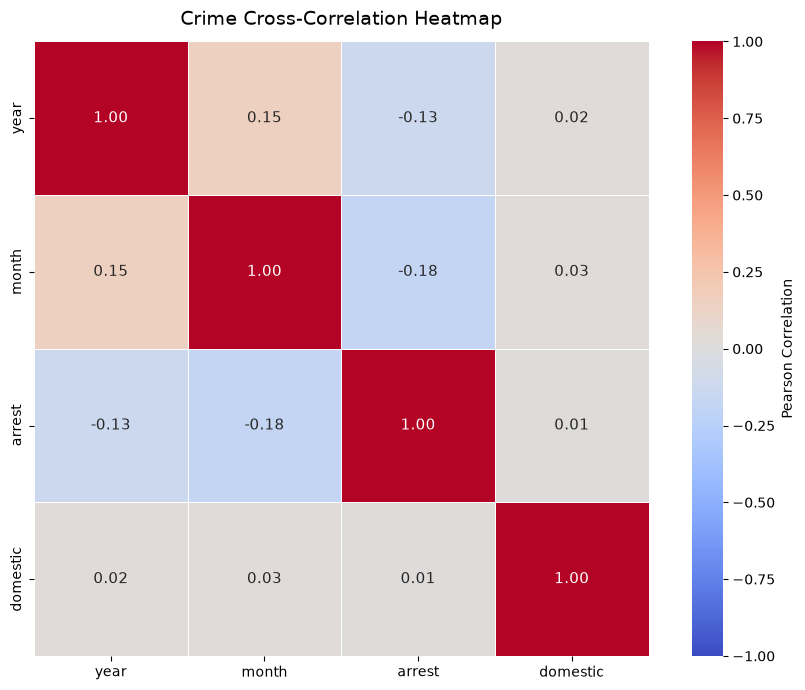


Chart Saved: crime_correlation_heatmap.png

========== CORRELATION INSIGHTS ==========
Year vs Month: 0.15
Year vs Arrest: -0.13
Month vs Arrest: -0.18
Arrest vs Domestic: 0.01

Interpretation: The selected features show mostly weak linear relationships.
Note: Correlation does not imply causation.

========== USE CASE 3 SUMMARY ==========
Task 1: Crime Intensity by Time
Task 2: Community Area Clusters Using NumPy
Task 3: Crime Cross-Correlation

USE CASE 3 - TASK 3: PASS
USE CASE 3: ANALYSIS COMPLETE


In [8]:

# ============================================================
# USE CASE 3 - CODE CELL 3
# TASK 3: CRIME CROSS-CORRELATION
# ============================================================

# Assessment Requirements:
# 1. Calculate Pearson correlation among numeric features.
# 2. Use Pandas corr() to generate a correlation matrix.
# 3. Visualize the correlation matrix using Seaborn heatmap.
#
# Methods Used:
# pd.read_csv() loads the cleaned crime dataset.
# pd.to_numeric() converts numerical fields.
# map() converts TRUE/FALSE values into numeric flags.
# corr(method="pearson") calculates linear correlations.
# sns.heatmap() visualizes the correlation matrix.
# savefig() saves the chart for the Flask dashboard.
#
# Selected Features:
# year, month, arrest, domestic



# ============================================================
# STEP 1: IMPORT REQUIRED LIBRARIES
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display


# ============================================================
# STEP 2: LOCATE PROJECT AND DATASET
# ============================================================

BASE_DIR = Path.cwd().resolve()

# If the notebook runs from the notebooks folder,
# move to the main project directory.
if BASE_DIR.name == "notebooks":
    BASE_DIR = BASE_DIR.parent

# Ensure the correct rebuild project is being used.
assert BASE_DIR.name == "Chicago_Crime_Capstone_2026", (
    f"Incorrect project directory: {BASE_DIR}"
)

# Use the feature-engineered dataset from Notebook 01.
DATA_FILE = (
    BASE_DIR / "data" / "cleaned" /
    "chicago_crime_features.csv"
)

# Store the chart for the Flask dashboard.
CHARTS_DIR = BASE_DIR / "static" / "charts"

CHARTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

assert DATA_FILE.is_file(), (
    f"Cleaned dataset not found: {DATA_FILE}"
)


# ============================================================
# STEP 3: LOAD THE CLEANED CRIME DATASET
# ============================================================

correlation_df = pd.read_csv(
    DATA_FILE,
    low_memory=False
)

# Verify original records and feature columns.
assert len(correlation_df) == 498
assert correlation_df.shape[1] == 22

print("========== DATASET INFORMATION ==========")
print("Total Crime Records:", len(correlation_df))
print("Total Columns:", correlation_df.shape[1])


# ============================================================
# STEP 4: SELECT NUMERIC FEATURES
# ============================================================

# Select only the four required analytical variables.
# Year and Month represent temporal features.
# Arrest and Domestic are binary crime indicators.
#
# Exclude location coordinates and identifiers to keep
# the correlation analysis focused and interpretable.

numeric_columns = [
    "year",
    "month",
    "arrest",
    "domestic"
]

# Check that all selected columns exist.
assert set(numeric_columns).issubset(
    correlation_df.columns
)

# Work with a copy to preserve the original DataFrame.
numeric_df = correlation_df[
    numeric_columns
].copy()


# ============================================================
# STEP 5: CONVERT FEATURES TO NUMERIC VALUES
# ============================================================

# Convert Year and Month to numeric format.
for column in ["year", "month"]:

    numeric_df[column] = pd.to_numeric(
        numeric_df[column],
        errors="coerce"
    )

# Convert Boolean crime indicators to 1 or 0.
# TRUE = 1 and FALSE = 0.
boolean_mapping = {
    "TRUE": 1,
    "FALSE": 0,
    "1": 1,
    "0": 0
}

for column in ["arrest", "domestic"]:

    numeric_df[column] = (
        numeric_df[column]
        .astype("string")
        .str.strip()
        .str.upper()
        .map(boolean_mapping)
    )

# Verify that all selected fields contain valid numbers.
assert numeric_df.notna().all().all(), (
    "Missing or invalid values found in numeric features."
)

print("\n========== SELECTED NUMERIC FEATURES ==========")
print(numeric_columns)


# ============================================================
# STEP 6: CALCULATE PEARSON CORRELATION MATRIX
# ============================================================

# Pearson correlation measures linear relationships.
#
# +1 represents perfect positive correlation.
#  0 represents no linear correlation.
# -1 represents perfect negative correlation.
#
# corr() automatically calculates correlation between
# every pair of selected numeric features.

correlation_matrix = numeric_df.corr(
    method="pearson"
)

print("\n========== PEARSON CORRELATION MATRIX ==========")

display(correlation_matrix.round(2))


# ============================================================
# STEP 7: GENERATE THE REQUIRED SEABORN HEATMAP
# ============================================================

# Create a 4x4 correlation heatmap

fig, ax = plt.subplots(figsize=(9, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5,
    square=True,
    cbar_kws={
        "label": "Pearson Correlation"
    },
    annot_kws={
        "size": 11
    },
    ax=ax
)

ax.set_title(
    "Crime Cross-Correlation Heatmap",
    fontsize=14,
    pad=12
)

# Rotate axis labels for better readability.
ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation=0
)

ax.set_yticklabels(
    ax.get_yticklabels(),
    rotation=90,
    va="center"
)

plt.tight_layout()


# ============================================================
# STEP 8: SAVE THE HEATMAP
# ============================================================

# Save using the same filename so the Flask dashboard
# can reference the updated chart without changes.
chart_path = (
    CHARTS_DIR / "crime_correlation_heatmap.png"
)

fig.savefig(
    chart_path,
    dpi=150,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("\nChart Saved:", chart_path.name)


# ============================================================
# STEP 9: DISPLAY CORRELATION INSIGHTS
# ============================================================

print("\n========== CORRELATION INSIGHTS ==========")

print(
    "Year vs Month:",
    f"{correlation_matrix.loc['year', 'month']:.2f}"
)

print(
    "Year vs Arrest:",
    f"{correlation_matrix.loc['year', 'arrest']:.2f}"
)

print(
    "Month vs Arrest:",
    f"{correlation_matrix.loc['month', 'arrest']:.2f}"
)

print(
    "Arrest vs Domestic:",
    f"{correlation_matrix.loc['arrest', 'domestic']:.2f}"
)

print(
    "\nInterpretation: The selected features show "
    "mostly weak linear relationships."
)

print(
    "Note: Correlation does not imply causation."
)


# ============================================================
# STEP 10: VALIDATE THE RESULTS
# ============================================================

# All 498 original crime records must be preserved.
assert len(correlation_df) == 498
assert len(numeric_df) == 498

# Four numeric features produce a 4x4 matrix.
assert correlation_matrix.shape == (4, 4)

# Verify no missing correlation results.
assert correlation_matrix.notna().all().all()

# Every variable must correlate perfectly with itself.
assert np.allclose(
    np.diag(correlation_matrix.to_numpy()),
    1.0
)

# Correlation matrices must be symmetric.
assert np.allclose(
    correlation_matrix.to_numpy(),
    correlation_matrix.to_numpy().T
)

# Verify the required heatmap was saved.
assert chart_path.is_file()
assert chart_path.stat().st_size > 0


# ============================================================
# STEP 11: FINAL COMPLETION STATUS
# ============================================================

print("\n========== USE CASE 3 SUMMARY ==========")

print("Task 1: Crime Intensity by Time")
print("Task 2: Community Area Clusters Using NumPy")
print("Task 3: Crime Cross-Correlation")

print("\nUSE CASE 3 - TASK 3: PASS")
print("USE CASE 3: ANALYSIS COMPLETE")
